# 07 · Selección del umbral y análisis de errores (solo validación)

> **Prototipo académico; no apto para diagnóstico ni decisiones clínicas.**

**Criterio (fijado antes de ver la tabla):** el umbral es el **más alto** de la rejilla 0,05 a
0,95 (pasos de 0,05) con el que la **sensibilidad en validación es al menos 0,80**.
- Sensibilidad mínima: un falso negativo (no detectar una lesión maligna) es el error más
  costoso, como dice la hipótesis H2.
- El más alto: entre los umbrales que cumplen, es el que deja menos falsos positivos.
- Con 10 malignas en validación, 0,80 significa detectar al menos 8 de 10.

El umbral se guarda en `resultados/umbral_final.json` y **no se vuelve a cambiar** después de
ver la prueba. Requiere haber ejecutado el notebook 06.

In [1]:
# Montar Drive y fijar rutas (las mismas en todos los notebooks)
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE    = "/content/drive/MyDrive/Aprendizaje final"
DATA    = f"{BASE}/Csv"
RES     = f"{BASE}/resultados"
SRC     = f"{BASE}/src"
PART    = f"{RES}/particiones"
PNG     = f"{BASE}/procesadas_224"     # recortes preprocesados (no van a Git)
MODELOS = f"{BASE}/modelos"            # checkpoints .pt (no van a Git)
for p in [DATA, RES, SRC, PART]:
    assert os.path.exists(p), f"No existe: {p}"
sys.path.insert(0, SRC)

Mounted at /content/drive


In [2]:
import json, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
import modelo_utils as mu

SENS_OBJETIVO = 0.80
REJILLA = np.round(np.arange(0.05, 0.951, 0.05), 2)

final = json.load(open(f"{RES}/modelo_final.json"))
print("Modelo final:", final["condicion"], "| semilla", final["semilla"], "| AUC val", final["auc_val"])
val = pd.read_csv(f"{PART}/val.csv")
pred = pd.read_csv(f"{RES}/pred_val_final.csv")
assert set(pred.lesion_id) == set(val.lesion_id)
print("Validación:", len(pred), "lesiones,", int(pred.label.sum()), "malignas")

Modelo final: sin_aumentos | semilla 42 | AUC val 0.881
Validación: 37 lesiones, 10 malignas


## Tabla de umbrales y elección

In [3]:
def elegir_umbral(p):
    t = mu.tabla_umbrales(p, REJILLA)
    ok = t[t.sensibilidad >= SENS_OBJETIVO]
    return (float(ok.umbral.max()) if len(ok) else float(REJILLA.min())), t

UMBRAL, tabla = elegir_umbral(pred)
tabla.round(3).to_csv(f"{RES}/umbrales_val_final.csv", index=False)
print(tabla.round(3).to_string(index=False))
print(f"\nUmbral elegido: {UMBRAL}")

 umbral  TP  FN  TN  FP  sensibilidad  sens_ic95  especificidad  esp_ic95  precision    f1
   0.05  10   0   4  23           1.0  0.72-1.00          0.148 0.06-0.32      0.303 0.465
   0.10  10   0   9  18           1.0  0.72-1.00          0.333 0.19-0.52      0.357 0.526
   0.15  10   0  14  13           1.0  0.72-1.00          0.519 0.34-0.69      0.435 0.606
   0.20   9   1  16  11           0.9  0.60-0.98          0.593 0.41-0.75      0.450 0.600
   0.25   9   1  20   7           0.9  0.60-0.98          0.741 0.55-0.87      0.562 0.692
   0.30   8   2  23   4           0.8  0.49-0.94          0.852 0.68-0.94      0.667 0.727
   0.35   6   4  25   2           0.6  0.31-0.83          0.926 0.77-0.98      0.750 0.667
   0.40   4   6  26   1           0.4  0.17-0.69          0.963 0.82-0.99      0.800 0.533
   0.45   3   7  26   1           0.3  0.11-0.60          0.963 0.82-0.99      0.750 0.429
   0.50   3   7  26   1           0.3  0.11-0.60          0.963 0.82-0.99      0.750 0.429

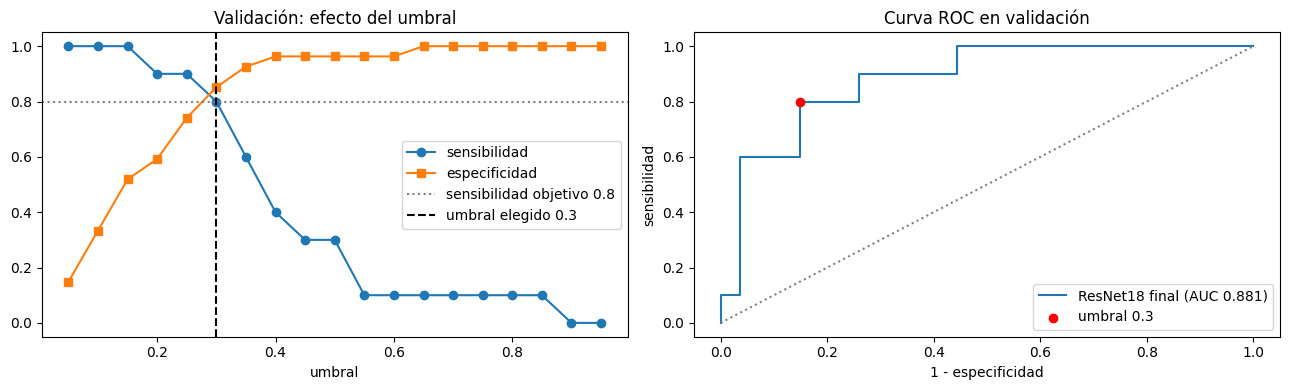

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(tabla.umbral, tabla.sensibilidad, "o-", label="sensibilidad")
ax[0].plot(tabla.umbral, tabla.especificidad, "s-", label="especificidad")
ax[0].axhline(SENS_OBJETIVO, ls=":", c="gray", label=f"sensibilidad objetivo {SENS_OBJETIVO}")
ax[0].axvline(UMBRAL, ls="--", c="k", label=f"umbral elegido {UMBRAL}")
ax[0].set_xlabel("umbral"); ax[0].set_title("Validación: efecto del umbral"); ax[0].legend()

fpr, tpr, _ = roc_curve(pred.label, pred.score)
m = mu.metricas(pred.label, pred.score, UMBRAL)
ax[1].plot(fpr, tpr, label=f"ResNet18 final (AUC {final['auc_val']:.3f})")
ax[1].plot([0, 1], [0, 1], ":", c="gray")
ax[1].scatter(1 - m["especificidad"], m["sensibilidad"], c="r", zorder=3, label=f"umbral {UMBRAL}")
ax[1].set_xlabel("1 - especificidad"); ax[1].set_ylabel("sensibilidad")
ax[1].set_title("Curva ROC en validación"); ax[1].legend()
plt.tight_layout()
plt.savefig(f"{RES}/umbral_validacion.png", dpi=110, bbox_inches="tight")
plt.show()

## Estabilidad del umbral
Se remuestrean **pacientes** de validación 1000 veces y en cada muestra se aplica la misma regla.
Si el umbral elegido cambia mucho entre muestras, hay que decirlo: con 10 malignas, el umbral
depende de muy pocos casos.

In [5]:
rng = np.random.default_rng(0)
grupos = {p: g for p, g in pred.groupby("patient_id")}
pacs = list(grupos)
umbrales_boot = []
for _ in range(1000):
    mb = pd.concat([grupos[p] for p in rng.choice(pacs, len(pacs), replace=True)])
    if mb.label.sum() > 0:
        umbrales_boot.append(elegir_umbral(mb)[0])
ub = pd.Series(umbrales_boot)
print("Umbral elegido en las muestras bootstrap (frecuencia):")
print(ub.value_counts().sort_index().to_string())
print(f"Percentiles 2.5 / 50 / 97.5: {ub.quantile(.025):.2f} / {ub.median():.2f} / {ub.quantile(.975):.2f}")

Umbral elegido en las muestras bootstrap (frecuencia):
0.15    126
0.25    302
0.30    364
0.35    142
0.40     49
0.50     15
Percentiles 2.5 / 50 / 97.5: 0.15 / 0.30 / 0.40


In [6]:
s_lo, s_hi = mu.wilson(m["TP"], m["TP"] + m["FN"])
guardado = dict(umbral=UMBRAL, criterio=f"umbral más alto con sensibilidad de validación >= {SENS_OBJETIVO}",
                modelo=final["ckpt"], sens_val=round(m["sensibilidad"], 3), sens_val_ic95=m["sens_ic95"],
                esp_val=round(m["especificidad"], 3), esp_val_ic95=m["esp_ic95"],
                umbral_bootstrap_p2_5=float(ub.quantile(.025)), umbral_bootstrap_p97_5=float(ub.quantile(.975)),
                fecha=datetime.datetime.now().strftime("%Y-%m-%d %H:%M"))
json.dump(guardado, open(f"{RES}/umbral_final.json", "w"), indent=1, ensure_ascii=False)
print(json.dumps(guardado, indent=1, ensure_ascii=False))

{
 "umbral": 0.3,
 "criterio": "umbral más alto con sensibilidad de validación >= 0.8",
 "modelo": "exp_sin_aumentos_s42.pt",
 "sens_val": 0.8,
 "sens_val_ic95": "0.49-0.94",
 "esp_val": 0.852,
 "esp_val_ic95": "0.68-0.94",
 "umbral_bootstrap_p2_5": 0.15,
 "umbral_bootstrap_p97_5": 0.4,
 "fecha": "2026-11-21 22:13"
}


## Matriz de confusión y errores con el umbral elegido

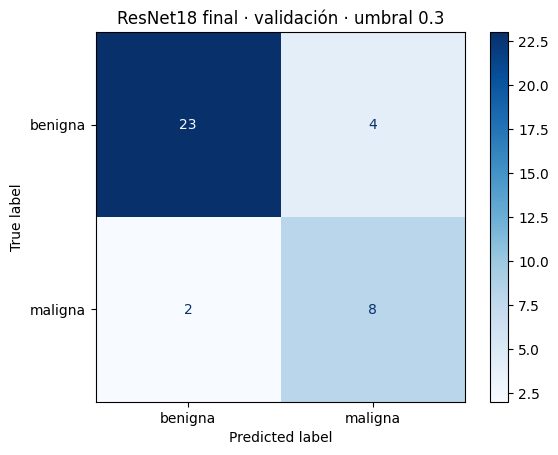

Falsos negativos (2):
          lesion_id patient_id  label    score
 P_00324_RIGHT_CC_1    P_00324      1 0.175724
P_00324_RIGHT_MLO_1    P_00324      1 0.274406

Falsos positivos (4):
         lesion_id patient_id  label    score
P_00429_LEFT_MLO_1    P_00429      0 0.616333
P_00124_RIGHT_CC_1    P_00124      0 0.382062
 P_00065_LEFT_CC_1    P_00065      0 0.326535
P_00173_LEFT_MLO_1    P_00173      0 0.315612


In [7]:
p = pred.merge(val.drop(columns=["label", "patient_id"]), on="lesion_id")
p["pred"] = (p.score >= UMBRAL).astype(int)
p["resultado"] = np.select([(p.label == 1) & (p.pred == 1), (p.label == 1) & (p.pred == 0),
                            (p.label == 0) & (p.pred == 0)], ["TP", "FN", "TN"], "FP")

ConfusionMatrixDisplay.from_predictions(p.label, p.pred, display_labels=["benigna", "maligna"], cmap="Blues")
plt.title(f"ResNet18 final · validación · umbral {UMBRAL}")
plt.savefig(f"{RES}/matriz_confusion_val_final.png", dpi=110, bbox_inches="tight")
plt.show()

cols = ["lesion_id", "patient_id", "label", "score"]
fn = p[p.resultado == "FN"].sort_values("score")
fp = p[p.resultado == "FP"].sort_values("score", ascending=False)
print(f"Falsos negativos ({len(fn)}):"); print(fn[cols].to_string(index=False))
print(f"\nFalsos positivos ({len(fp)}):"); print(fp[cols].to_string(index=False))
p.to_csv(f"{RES}/errores_val_final.csv", index=False)

In [8]:
# Errores según variables del CSV (solo para describir; NO son entradas del modelo).
# Con tan pocos casos por grupo, son conteos, no conclusiones.
for c in ["image view", "left or right breast", "breast_density", "breast density",
          "subtlety", "mass shape", "mass margins"]:
    if c in p.columns:
        print(f"\n--- {c} ---")
        print(pd.crosstab(p[c], p.resultado))
print("\nErrores por paciente:")
print(p[p.resultado.isin(["FN", "FP"])].groupby("patient_id").resultado.agg(list).to_string())


--- image view ---
resultado   FN  FP  TN  TP
image view                
CC           1   2  13   4
MLO          1   2  10   4

--- left or right breast ---
resultado             FN  FP  TN  TP
left or right breast                
LEFT                   0   3   9   6
RIGHT                  2   1  14   2

--- breast_density ---
resultado       FN  FP  TN  TP
breast_density                
1                0   0   0   2
2                0   3  18   4
3                2   1   5   0
4                0   0   0   2

--- subtlety ---
resultado  FN  FP  TN  TP
subtlety                 
2           1   0   3   0
3           1   0   1   2
4           0   1   7   2
5           0   3  12   4

--- mass shape ---
resultado                           FN  FP  TN  TP
mass shape                                        
IRREGULAR                            1   0   0   4
IRREGULAR-ARCHITECTURAL_DISTORTION   1   0   0   0
LOBULATED                            0   2   7   2
OVAL                               

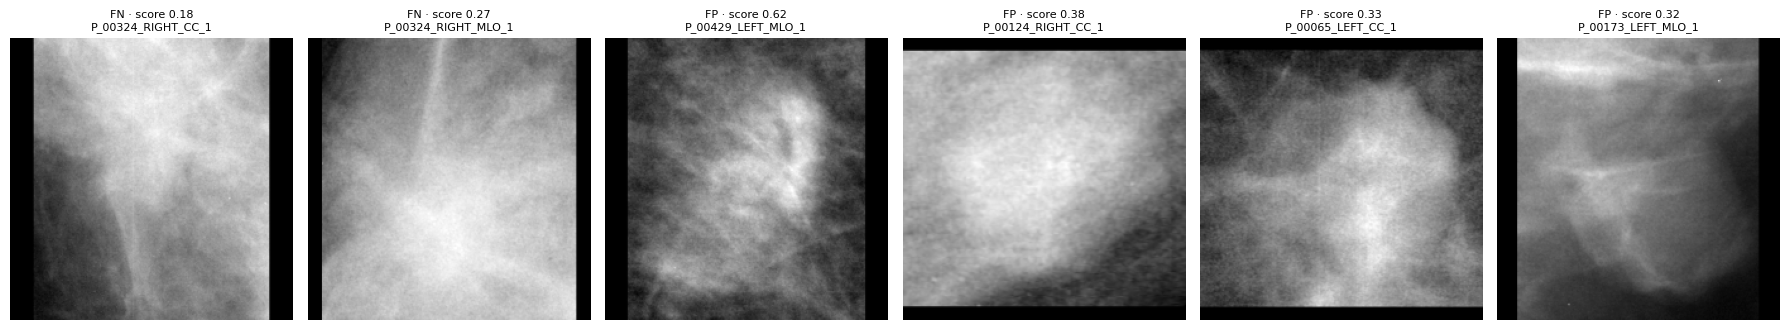

In [9]:
errores = pd.concat([fn, fp])
if len(errores):
    n = len(errores); cols_fig = min(n, 6); filas_fig = int(np.ceil(n / cols_fig))
    fig, ax = plt.subplots(filas_fig, cols_fig, figsize=(3 * cols_fig, 3.4 * filas_fig), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, r in zip(ax.ravel(), errores.itertuples()):
        a.imshow(Image.open(f"{PNG}/{r.lesion_id}.png"), cmap="gray")
        a.set_title(f"{r.resultado} · score {r.score:.2f}\n{r.lesion_id}", fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{RES}/errores_val_final.png", dpi=110, bbox_inches="tight")
    plt.show()

## Cómo leer el resultado (sin sobreinterpretar)
- La sensibilidad y la especificidad del umbral elegido son **de validación**: el umbral se
  ajustó a estas 37 lesiones, así que en la prueba lo normal es que salgan algo peores.
- La validación tiene 27 % de malignas y la prueba 39 %: la precisión cambiará con esa
  prevalencia; la sensibilidad y la especificidad no dependen de ella.
- En los errores, mira si se repiten pacientes. Varias lesiones de una misma paciente no son
  errores independientes.
- Describe lo que se ve en las imágenes de los errores (tamaño, contraste, bordes) sin afirmar
  causas que no se pueden comprobar con tan pocos casos.